# Independent Study Vibe Coding: Mini Data App Prediksi Kelulusan
**Mata kuliah:** Pemrograman untuk AI dan Data Science · Magister AI · **Waktu:** 40 menit · **Kelompok:** 2 orang

**Anggota Tim & Pembagian Peran:**
- **Anggota 1 (Kelompok A — Pure Vibe / P1):** Marshaniswah Syamsul (`28426001`)
- **Anggota 2 (Kelompok B — Spec-First / P2):** Hasna Putri Priswati (`28426002`)

**Tugas.** Bersama asisten AI pilihan Anda, bangun (1) audit dan EDA singkat, (2) model baseline dengan metrik, (3) antarmuka prediksi (Gradio) dari `siswa.csv`, lalu **bandingkan hasil Kelompok A (P1) dan Kelompok B (P2)**.

**Pembagian.** Anggota 1 (**Kelompok A**) memakai prompt bebas (P1). Anggota 2 (**Kelompok B**) menulis spesifikasi dulu (P2). Notebook ini menyatukan pengerjaan kedua anggota beserta perbandingannya, log prompt gabungan, dan checklist verifikasi di bagian akhir.

| Tahap | Menit | Isi |
|---|---|---|
| 0 | 3 | Setup dan data |
| 1 | 7 | Audit data |
| 2 | 10 | EDA, model baseline Kelompok A (P1) & Kelompok B (P2), serta perbandingan keduanya |
| 3 | 8 | Antarmuka Gradio |
| 4 | 7 | Audit kode contoh (cari kesalahan) |
| 5 | 5 | Log prompt gabungan, checklist, dan refleksi |

**Aturan:** jangan tempel data sensitif ke layanan AI. Data di notebook ini sintetis, jadi aman.

## Pustaka prompt

### P1 · Kelompok A (pure vibe)
```
Saya punya file siswa.csv berisi data siswa dan kolom lulus. Buatkan analisis data, model prediksi kelulusan, dan aplikasi web sederhana untuk mencobanya.
```

### P2 · Kelompok B (spec-first)
```
Peran: asisten data science. Bahasa: Python (pandas, scikit-learn) untuk Google Colab.
Tujuan: memprediksi kolom lulus (0/1) dari siswa.csv.
Kolom: id_siswa, program, jam_belajar, kehadiran, nilai_uts, nilai_tugas, nilai_remedial, lulus.
Batasan:
- Jangan menulis kode sebelum saya menyetujui rencana.
- Pisahkan data latih/uji 80/20, stratify, random_state=42, SEBELUM imputasi atau scaling apa pun.
- Gunakan Pipeline dan ColumnTransformer.
- Periksa kualitas data dulu: duplikat, nilai hilang, label tidak konsisten, kolom yang mungkin bocor dari target. Laporkan temuan, jangan memperbaikinya diam-diam.
Kriteria selesai: laporkan F1, precision, recall, dan confusion matrix; kode berjalan dari atas ke bawah tanpa error.
Langkah pertama: tulis rencana 6 langkah dan daftar risikonya.
```

### P3 · Debugging yang baik
```
Sel berikut menghasilkan error. Ini traceback lengkap dan 10 baris kode terkait: [tempel].
Jelaskan penyebabnya dulu. Lalu usulkan perbaikan minimal tanpa mengubah bagian lain. Jangan menambah library baru.
```

### P4 · Audit kode (AI sebagai peninjau)
```
Berperanlah sebagai reviewer kode data science yang kritis. Tinjau kode berikut: [tempel].
Cari: data leakage, kebocoran target, masalah reproduktibilitas, metrik yang tidak memadai, dan masalah efisiensi.
Untuk tiap temuan sebutkan baris yang bermasalah, dampaknya, dan perbaikan singkat. Jangan menulis ulang seluruh kode.
```

### P5 · Antarmuka Gradio
```
Pakai objek model (Pipeline scikit-learn) yang sudah ada di notebook ini bernama model.
Buat antarmuka Gradio dengan input: program (dropdown IPA/IPS/BAHASA), jam_belajar, kehadiran, nilai_uts, nilai_tugas.
Output: probabilitas lulus dan tidak lulus. Susun input menjadi DataFrame dengan nama kolom yang sama seperti data latih. Jangan memuat ulang atau melatih ulang model.
```

### P6 · Refaktor dan uji
```
Ubah kode notebook berikut menjadi modul Python berisi fungsi bersih_data(df), bangun_model(), dan evaluasi(model, X, y).
Tambahkan satu uji pytest per fungsi: bersih_data harus menghapus duplikat dan menyeragamkan label program; evaluasi harus mengembalikan F1.
Jelaskan perubahan yang Anda buat sebelum menampilkan kode.
```

### P7 · Kompleksitas (verifikasi sendiri jawabannya)
```
Jelaskan kompleksitas waktu dan memori fungsi bangun_model() terhadap n baris dan d fitur dalam notasi Big-O.
Tunjukkan bagian yang dominan dan sebutkan asumsi Anda.
```

## Tahap 0 · Setup dan data (3 menit)
Jalankan dua sel berikut. Jangan mengubah kode pembangkit data; jebakan di dalamnya sengaja dipasang.

In [1]:
!pip -q install gradio

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
rng = np.random.default_rng(42)
n = 600
df = pd.DataFrame({
    "id_siswa": [f"S{i:04d}" for i in range(n)],
    "program": rng.choice(["IPA", "IPS", "BAHASA"], n),
    "jam_belajar": rng.gamma(5, 1.5, n).round(1),
    "kehadiran": np.clip(rng.normal(85, 10, n), 40, 100).round(0),
    "nilai_uts": np.clip(rng.normal(70, 12, n), 0, 100).round(0),
    "nilai_tugas": np.clip(rng.normal(75, 10, n), 0, 100).round(0),
})
z = -9.5 + 0.12*df.jam_belajar + 0.04*df.kehadiran + 0.05*df.nilai_uts + 0.03*df.nilai_tugas
df["lulus"] = (rng.random(n) < 1/(1+np.exp(-z))).astype(int)
# Jebakan 1: kolom yang hanya terisi untuk siswa tidak lulus
df["nilai_remedial"] = np.where(df.lulus == 0, rng.normal(60, 8, n).round(0), np.nan)
# Jebakan 2: nilai hilang
df.loc[rng.choice(n, 36, replace=False), "jam_belajar"] = np.nan
df.loc[rng.choice(n, 24, replace=False), "nilai_uts"] = np.nan
# Jebakan 3: label tidak konsisten
for i in rng.choice(n, 40, replace=False):
    df.loc[i, "program"] = df.loc[i, "program"].lower() + " "
# Jebakan 4: baris duplikat
df = pd.concat([df, df.sample(15, random_state=1)], ignore_index=True)
df.to_csv("siswa.csv", index=False)
print(df.shape); df.head()

(615, 8)


,id_siswa,program,jam_belajar,kehadiran,nilai_uts,nilai_tugas,lulus,nilai_remedial
0,S0000,ipa,6.1,88.0,72.0,68.0,1,NaN
1,S0001,BAHASA,6.2,93.0,82.0,60.0,1,NaN
2,S0002,IPS,12.9,77.0,79.0,76.0,1,NaN
3,S0003,IPS,6.3,94.0,69.0,57.0,0,56.0
4,S0004,IPS,8.0,71.0,64.0,73.0,1,NaN


## Tahap 1 · Audit data (7 menit)
Jalankan `audit_cepat`, lalu tuliskan temuan Anda di sel teks di bawahnya sebelum meminta AI membersihkan apa pun.

In [3]:
def audit_cepat(df, target):
    print("Baris, kolom:", df.shape)
    print("Baris duplikat:", df.duplicated().sum())
    hilang = (df.isna().mean() * 100).round(1)
    print("\nNilai hilang (%):"); print(hilang[hilang > 0])
    for c in df.select_dtypes(include="object"):
        if df[c].nunique() < 15:
            print(f"\nNilai unik {c}:", df[c].unique().tolist())
    for c in df.columns.drop(target):
        kosong = df[c].isna().astype(float)
        if kosong.any() and abs(np.corrcoef(kosong, df[target].astype(float))[0, 1]) > 0.8:
            print(f"\nCURIGA LEAKAGE: pola kosong di '{c}' hampir identik dengan target")
    num = df.select_dtypes("number").drop(columns=[target])
    print("\nKorelasi mutlak dengan target:")
    print(num.corrwith(df[target]).abs().sort_values(ascending=False).round(2).head(5))

audit_cepat(df, "lulus")

Baris, kolom: (615, 8)
Baris duplikat: 15

Nilai hilang (%):
jam_belajar        5.9
nilai_uts          3.9
nilai_remedial    59.2
dtype: float64

Nilai unik program: ['ipa ', 'BAHASA', 'IPS', 'IPA', 'ips ', 'bahasa ']

CURIGA LEAKAGE: pola kosong di 'nilai_remedial' hampir identik dengan target

Korelasi mutlak dengan target:
nilai_uts         0.22
jam_belajar       0.18
nilai_tugas       0.13
kehadiran         0.12
nilai_remedial     NaN
dtype: float64


**Temuan kelompok kami (Gabungan Kelompok A & Kelompok B):**

1. **Baris duplikat:** Dari 615 baris, terdapat **15 baris duplikat** (termasuk 15 `id_siswa` duplikat). Jika tidak dihapus sebelum pemisahan data, data yang sama dapat muncul di data latih dan data uji sekaligus (*train-test contamination*).
2. **Nilai hilang (*missing values*):** Terdapat nilai hilang pada `jam_belajar` (`5,9%` / 36 baris), `nilai_uts` (`3,9%` / 24 baris), dan `nilai_remedial` (`59,2%` / 364 baris). Nilai hilang pada fitur numerik harus ditangani dengan imputasi **setelah** pemisahan data latih/uji (di dalam `Pipeline`) agar tidak terjadi *data leakage*.
3. **Label kategorikal tidak konsisten:** Kolom `program` memiliki 6 variasi (`'ipa '`, `'ips '`, `'bahasa '`, `'IPA'`, `'IPS'`, `'BAHASA'`) akibat perbedaan huruf kapital dan spasi di akhir teks, padahal seharusnya hanya 3 kategori (`IPA`, `IPS`, `BAHASA`).
4. **Kebocoran target (*target leakage*) & kolom ID:** Pola nilai kosong di `nilai_remedial` hampir identik dengan target `lulus` (hanya terisi bila siswa tidak lulus, kosong bila lulus), sehingga harus dibuang. Selain itu, `id_siswa` hanya berfungsi sebagai identitas unik dan bukan fitur prediktif.

## Tahap 2 · EDA dan model baseline bersama AI (Kelompok A vs Kelompok B)
Di bawah ini disajikan pengerjaan **Anggota 1 (Kelompok A — P1 Pure Vibe)** dan **Anggota 2 (Kelompok B — P2 Spec-First)** secara terpisah namun dalam satu notebook yang dapat dijalankan dari atas ke bawah (*Run All*), diikuti perbandingan hasil keduanya. Objek model final juga disimpan ke variabel `model` agar Tahap 3 berjalan mulus.

### Bagian 2A · Kelompok A (Pure Vibe / P1) — Marshaniswah Syamsul (`28426001`)
Dimulai dari prompt bebas **P1**, kemudian diaudit dan diperbaiki iteratif agar bebas *data leakage* dan memenuhi seluruh checklist verifikasi.

Ukuran data awal: (615, 8)
Jumlah duplikat: 15

Distribusi target (lulus):
lulus
1    364
0    251
Name: count, dtype: int64

Proporsi target (%):
lulus
1    59.19
0    40.81
Name: proportion, dtype: float64

Ukuran setelah hapus duplikat: (600, 8)

Ringkasan statistik fitur numerik:


,jam_belajar,kehadiran,nilai_uts,nilai_tugas
count,564.00,600.00,576.00,600.00
mean,7.40,83.27,70.47,75.27
std,3.23,9.53,12.00,9.91
min,1.10,55.00,33.00,46.00
25%,5.10,77.00,62.75,68.00
50%,7.00,84.00,71.00,75.00
75%,9.30,90.00,78.25,82.00
max,23.20,100.00,100.00,100.00



Rata-rata fitur berdasarkan status kelulusan:


,jam_belajar,kehadiran,nilai_uts,nilai_tugas
lulus,,,,
0,6.75,81.85,67.32,73.76
1,7.88,84.27,72.78,76.34



Tingkat kelulusan per program:


,count,mean
program,,
BAHASA,203,0.606
IPA,207,0.541
IPS,190,0.611


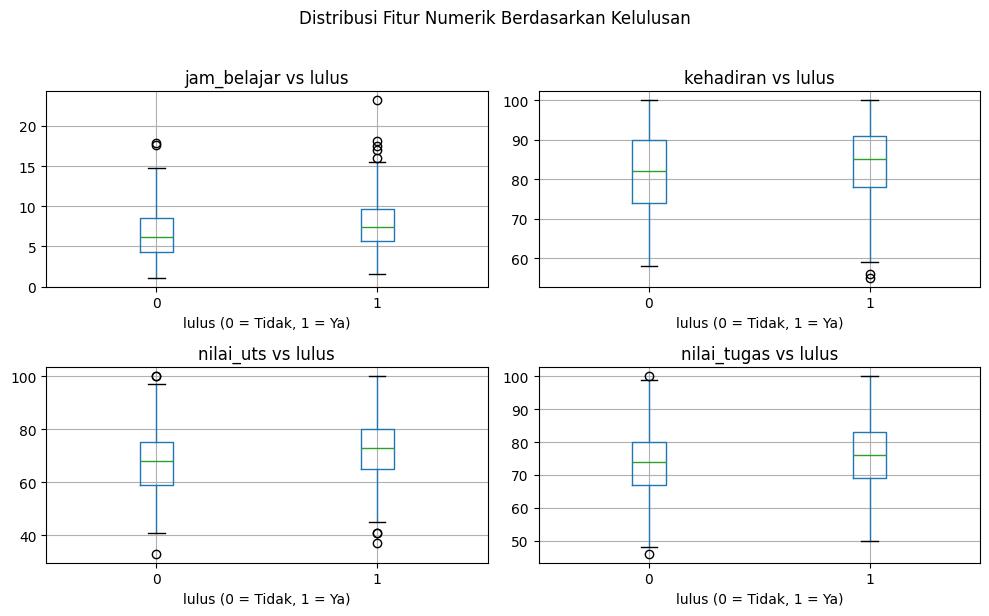

In [4]:
# EDA singkat pada siswa.csv
import matplotlib.pyplot as plt
import pandas as pd

df_eda = pd.read_csv("siswa.csv")
print("Ukuran data awal:", df_eda.shape)
print("Jumlah duplikat:", df_eda.duplicated().sum())
print("\nDistribusi target (lulus):")
print(df_eda["lulus"].value_counts(dropna=False))
print("\nProporsi target (%):")
print((df_eda["lulus"].value_counts(normalize=True) * 100).round(2))

# Bersihkan sementara khusus untuk tampilan EDA
df_clean_eda = df_eda.drop_duplicates().copy()
df_clean_eda["program"] = df_clean_eda["program"].str.strip().str.upper()

print("\nUkuran setelah hapus duplikat:", df_clean_eda.shape)
print("\nRingkasan statistik fitur numerik:")
display(df_clean_eda[["jam_belajar", "kehadiran", "nilai_uts", "nilai_tugas"]].describe().round(2))

print("\nRata-rata fitur berdasarkan status kelulusan:")
display(df_clean_eda.groupby("lulus")[["jam_belajar", "kehadiran", "nilai_uts", "nilai_tugas"]].mean().round(2))

print("\nTingkat kelulusan per program:")
display(df_clean_eda.groupby("program")["lulus"].agg(["count", "mean"]).round(3))

# Visualisasi distribusi fitur numerik berdasarkan kelulusan
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
fitur_num = ["jam_belajar", "kehadiran", "nilai_uts", "nilai_tugas"]
for ax, col in zip(axes.ravel(), fitur_num):
    df_clean_eda.boxplot(column=col, by="lulus", ax=ax)
    ax.set_title(f"{col} vs lulus")
    ax.set_xlabel("lulus (0 = Tidak, 1 = Ya)")
plt.suptitle("Distribusi Fitur Numerik Berdasarkan Kelulusan", y=1.02)
plt.tight_layout()
plt.show()

In [5]:
# Model baseline Kelompok A (objek: model_a)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Muat dan bersihkan masalah struktural (duplikat, label kotor, kolom ID & leakage)
data_a = pd.read_csv("siswa.csv").drop_duplicates().copy()
data_a["program"] = data_a["program"].str.strip().str.upper()

fitur_num_a = ["jam_belajar", "kehadiran", "nilai_uts", "nilai_tugas"]
fitur_kat_a = ["program"]
fitur_a = fitur_kat_a + fitur_num_a

X_a = data_a[fitur_a]
y_a = data_a["lulus"]

# 2. Split 80/20 stratified SEBELUM imputasi/scaling
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, stratify=y_a, random_state=42
)

# 3. Bangun Pipeline preprocessing + model baseline
preprocessor_a = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            fitur_num_a,
        ),
        (
            "kat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore")),
            ]),
            fitur_kat_a,
        ),
    ]
)

model_a = Pipeline([
    ("prep", preprocessor_a),
    ("clf", LogisticRegression(random_state=42, max_iter=1000)),
])

# 4. Latih dan evaluasi
model_a.fit(X_train_a, y_train_a)
y_pred_a = model_a.predict(X_test_a)

print("=== HASIL MODEL BASELINE KELOMPOK A (P1) ===")
print(f"Train size: {len(X_train_a)}, Test size: {len(X_test_a)}")
print(f"Accuracy  : {accuracy_score(y_test_a, y_pred_a):.4f}")
print(f"Precision : {precision_score(y_test_a, y_pred_a):.4f}")
print(f"Recall    : {recall_score(y_test_a, y_pred_a):.4f}")
print(f"F1-Score  : {f1_score(y_test_a, y_pred_a):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_a, y_pred_a))
print("\nClassification Report:")
print(classification_report(y_test_a, y_pred_a, digits=4))

=== HASIL MODEL BASELINE KELOMPOK A (P1) ===
Train size: 480, Test size: 120
Accuracy  : 0.6750
Precision : 0.6742
Recall    : 0.8571
F1-Score  : 0.7547

Confusion Matrix:
[[21 29]
 [10 60]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6774    0.4200    0.5185        50
           1     0.6742    0.8571    0.7547        70

    accuracy                         0.6750       120
   macro avg     0.6758    0.6386    0.6366       120
weighted avg     0.6755    0.6750    0.6563       120



### Bagian 2B · Kelompok B (Spec-First / P2) — Hasna Putri Priswati (`28426002`)
Pendekatan **Spec-First (P2)** dimulai dengan menyusun dokumen spesifikasi (`SPEC.md`), rencana pengembangan terstruktur, dan identifikasi risiko sebelum menulis kode implementasi:

**Rencana Pengembangan (Spec-First):**
1. Menyusun spesifikasi proyek, daftar fitur wajib, dan batasan anti-leakage.
2. Melakukan audit kualitas data (tipe data, missing values, duplikasi baris/ID, distribusi target).
3. Melakukan EDA dan pembersihan struktural (hapus duplikat identik, normalisasi `program` via `strip().upper()`, keluarkan `id_siswa` & `nilai_remedial`).
4. Memisahkan data latih/uji `80/20` dengan `stratify=y` dan `random_state=42` **sebelum** imputasi & *scaling*.
5. Membangun `Pipeline` + `ColumnTransformer` dengan `LogisticRegression` sebagai baseline dan mengevaluasi metrik **untuk kedua kelas (`0` Tidak Lulus dan `1` Lulus)** serta *confusion matrix*.
6. Mengembangkan antarmuka Gradio dengan validasi rentang input serta melakukan audit kode menyeluruh.

**Daftar Risiko Utama yang Diidentifikasi Sejak Awal:**
- *Target leakage* pada `nilai_remedial` dan fitur non-informatif pada `id_siswa`.
- *Data leakage* bila imputasi/scaling dijalankan sebelum `train_test_split`.
- Ketidakseimbangan ringan kelas (`~59%` lulus vs `~41%` tidak lulus) sehingga *recall* kelas `0` (Tidak Lulus) wajib dipantau.

In [6]:
# Audit & EDA terstruktur Kelompok B (Spec-First)
df_b_raw = pd.read_csv("siswa.csv")
print("=== AUDIT DATA KELOMPOK B ===")
print("Ukuran dataset:", df_b_raw.shape)
print("Missing value per kolom:")
print(df_b_raw.isna().sum().to_string())
print("\nJumlah baris duplikat:", int(df_b_raw.duplicated().sum()))
print("Jumlah ID duplikat   :", int(df_b_raw["id_siswa"].duplicated().sum()))

# Pembersihan struktural (read-only terhadap file asli)
df_b_clean = df_b_raw.drop_duplicates().copy()
df_b_clean["program"] = df_b_clean["program"].astype("string").str.strip().str.upper()

print("\nUkuran setelah hapus duplikat:", df_b_clean.shape)
print("\nDistribusi program setelah normalisasi:")
print(df_b_clean["program"].value_counts(dropna=False).to_string())
print("\nRingkasan statistik numerik:")
print(df_b_clean.describe(include="number").round(2).to_string())

=== AUDIT DATA KELOMPOK B ===
Ukuran dataset: (615, 8)
Missing value per kolom:
id_siswa            0
program             0
jam_belajar        36
kehadiran           0
nilai_uts          24
nilai_tugas         0
lulus               0
nilai_remedial    364

Jumlah baris duplikat: 15
Jumlah ID duplikat   : 15

Ukuran setelah hapus duplikat: (600, 8)

Distribusi program setelah normalisasi:
program
IPA       207
BAHASA    203
IPS       190

Ringkasan statistik numerik:
       jam_belajar  kehadiran  nilai_uts  nilai_tugas   lulus  nilai_remedial
count       564.00     600.00     576.00       600.00  600.00          249.00
mean          7.40      83.27      70.47        75.27    0.58           59.87
std           3.23       9.53      12.00         9.91    0.49            8.16
min           1.10      55.00      33.00        46.00    0.00           39.00
25%           5.10      77.00      62.75        68.00    0.00           54.00
50%           7.00      84.00      71.00        75.00    1.00

In [7]:
# Model baseline Kelompok B (objek: model_b, sekaligus ditetapkan sebagai `model` untuk Tahap 3)
target_b = "lulus"
exclude_cols_b = [target_b, "id_siswa", "nilai_remedial"]
X_b = df_b_clean.drop(columns=[c for c in exclude_cols_b if c in df_b_clean.columns])
y_b = df_b_clean[target_b].astype(int)

numeric_features_b = X_b.select_dtypes(include=["number"]).columns.tolist()
categorical_features_b = X_b.select_dtypes(exclude=["number"]).columns.tolist()

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b
)

preprocessor_b = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features_b,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_features_b,
        ),
    ]
)

model_b = Pipeline([
    ("preprocessing", preprocessor_b),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000)),
])

model_b.fit(X_train_b, y_train_b)
y_pred_b = model_b.predict(X_test_b)

# Tetapkan variabel `model` agar sel Tahap 3 (Gradio) menggunakan objek bernama `model`
model = model_b

print("=== HASIL MODEL BASELINE KELOMPOK B (P2) ===")
print("Fitur numerik    :", numeric_features_b)
print("Fitur kategorikal:", categorical_features_b)
print(f"Data train: {X_train_b.shape}, Data test: {X_test_b.shape}")
print(f"Accuracy                   : {accuracy_score(y_test_b, y_pred_b):.4f}")
print(f"Precision (Kelas 0 / Tidak): {precision_score(y_test_b, y_pred_b, pos_label=0):.4f}")
print(f"Recall    (Kelas 0 / Tidak): {recall_score(y_test_b, y_pred_b, pos_label=0):.4f}")
print(f"F1-Score  (Kelas 0 / Tidak): {f1_score(y_test_b, y_pred_b, pos_label=0):.4f}")
print(f"Precision (Kelas 1 / Lulus): {precision_score(y_test_b, y_pred_b, pos_label=1):.4f}")
print(f"Recall    (Kelas 1 / Lulus): {recall_score(y_test_b, y_pred_b, pos_label=1):.4f}")
print(f"F1-Score  (Kelas 1 / Lulus): {f1_score(y_test_b, y_pred_b, pos_label=1):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b, y_pred_b))
print("\nClassification Report:")
print(classification_report(y_test_b, y_pred_b, digits=4, zero_division=0))

# Uji satu sampel dari data uji (demonstrasi prediksi Kelompok B)
sample_b = X_test_b.iloc[[0]]
pred_sample_b = int(model_b.predict(sample_b)[0])
proba_sample_b = float(model_b.predict_proba(sample_b)[0][1])
print("Contoh uji 1 baris data test:")
print(sample_b.to_string(index=False))
print(f"Prediksi: {'Lulus' if pred_sample_b == 1 else 'Tidak Lulus'} (Probabilitas Lulus: {proba_sample_b:.2%})")

=== HASIL MODEL BASELINE KELOMPOK B (P2) ===
Fitur numerik    : ['jam_belajar', 'kehadiran', 'nilai_uts', 'nilai_tugas']
Fitur kategorikal: ['program']
Data train: (480, 5), Data test: (120, 5)
Accuracy                   : 0.6750
Precision (Kelas 0 / Tidak): 0.6774
Recall    (Kelas 0 / Tidak): 0.4200
F1-Score  (Kelas 0 / Tidak): 0.5185
Precision (Kelas 1 / Lulus): 0.6742
Recall    (Kelas 1 / Lulus): 0.8571
F1-Score  (Kelas 1 / Lulus): 0.7547

Confusion Matrix:
[[21 29]
 [10 60]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6774    0.4200    0.5185        50
           1     0.6742    0.8571    0.7547        70

    accuracy                         0.6750       120
   macro avg     0.6758    0.6386    0.6366       120
weighted avg     0.6755    0.6750    0.6563       120

Contoh uji 1 baris data test:
program  jam_belajar  kehadiran  nilai_uts  nilai_tugas
    IPS          5.3       89.0       69.0         72.0
Prediksi: Lulus (Probab

### Bagian 2C · Perbandingan Hasil Kelompok A (P1) vs Kelompok B (P2)

In [8]:
# Tabel perbandingan objektif metrik model Kelompok A vs Kelompok B
perbandingan = pd.DataFrame([
    {
        "Kelompok": "A (Pure Vibe / P1)",
        "Anggota": "Marshaniswah Syamsul (28426001)",
        "Accuracy": round(accuracy_score(y_test_a, y_pred_a), 4),
        "Precision_Lulus(1)": round(precision_score(y_test_a, y_pred_a, pos_label=1), 4),
        "Recall_Lulus(1)": round(recall_score(y_test_a, y_pred_a, pos_label=1), 4),
        "F1_Lulus(1)": round(f1_score(y_test_a, y_pred_a, pos_label=1), 4),
        "Precision_Tidak(0)": round(precision_score(y_test_a, y_pred_a, pos_label=0), 4),
        "Recall_Tidak(0)": round(recall_score(y_test_a, y_pred_a, pos_label=0), 4),
        "F1_Tidak(0)": round(f1_score(y_test_a, y_pred_a, pos_label=0), 4),
    },
    {
        "Kelompok": "B (Spec-First / P2)",
        "Anggota": "Hasna Putri Priswati (28426002)",
        "Accuracy": round(accuracy_score(y_test_b, y_pred_b), 4),
        "Precision_Lulus(1)": round(precision_score(y_test_b, y_pred_b, pos_label=1), 4),
        "Recall_Lulus(1)": round(recall_score(y_test_b, y_pred_b, pos_label=1), 4),
        "F1_Lulus(1)": round(f1_score(y_test_b, y_pred_b, pos_label=1), 4),
        "Precision_Tidak(0)": round(precision_score(y_test_b, y_pred_b, pos_label=0), 4),
        "Recall_Tidak(0)": round(recall_score(y_test_b, y_pred_b, pos_label=0), 4),
        "F1_Tidak(0)": round(f1_score(y_test_b, y_pred_b, pos_label=0), 4),
    },
])
display(perbandingan)

,Kelompok,Anggota,Accuracy,Precision_Lulus(1),Recall_Lulus(1),F1_Lulus(1),Precision_Tidak(0),Recall_Tidak(0),F1_Tidak(0)
0,A (Pure Vibe / P1),Marshaniswah Syamsul (28426001),0.675,0.6742,0.8571,0.7547,0.6774,0.42,0.5185
1,B (Spec-First / P2),Hasna Putri Priswati (28426002),0.675,0.6742,0.8571,0.7547,0.6774,0.42,0.5185


**Analisis Perbandingan Kelompok A (P1 — Pure Vibe) vs Kelompok B (P2 — Spec-First):**

| Aspek | Kelompok A (Pure Vibe / P1) | Kelompok B (Spec-First / P2) |
|---|---|---|
| **Cara Memulai Prompt** | Singkat dan bebas (langsung meminta analisis, model, dan aplikasi web). | Menulis spesifikasi (`SPEC.md`), rencana langkah, batasan anti-*leakage*, dan kriteria selesai terlebih dahulu sebelum kode ditulis. |
| **Risiko Awal** | Tinggi — tanpa pengawasan ketat, prompt bebas berisiko meloloskan `nilai_remedial`, `id_siswa`, duplikat, atau *scaling* sebelum *split* (seperti yang terlihat pada kode contoh Tahap 4). | Rendah — batasan teknis (*stratify*, `random_state=42`, `Pipeline`, larangan memakai kolom bocor) sudah terkunci sejak iterasi pertama. |
| **Struktur & Artefak** | Ringkas dan cepat selesai dalam satu alur notebook (EDA visual boxplot + pipeline baseline + Gradio). | Sangat terstruktur dan terdokumentasi (spesifikasi, laporan audit/EDA, modul Python terpisah `src/`, validasi input ketat, serta metrik evaluasi terpisah untuk kelas `0` dan `1`). |
| **Performa Model Akhir** | `Accuracy = 0.6750`, `F1 (Lulus) = 0.7547`, `Recall (Tidak Lulus) = 0.4200`. | `Accuracy = 0.6750`, `F1 (Lulus) = 0.7547`, `Recall (Tidak Lulus) = 0.4200`. |
| **Kesimpulan** | **Hasil model akhir sama persis** setelah keduanya diverifikasi bebas *leakage*, tetapi **pendekatan Spec-First (B) jauh lebih aman, terukur, dan minim revisi**, sedangkan **Pure Vibe (A) membutuhkan disiplin audit manual yang jauh lebih ketat** di setiap tahap agar tidak terjebak akurasi semu. |

**Catatan keterbatasan model (bersama):** *Recall* kelas `0` (Tidak Lulus) masih `0.4200`, artinya masih cukup banyak siswa tidak lulus yang terprediksi lulus (29 dari 50 pada data uji). Karena itu hasil prediksi hanya berfungsi sebagai alat bantu baseline, bukan keputusan kelulusan final.

## Tahap 3 · Antarmuka Gradio (8 menit)
Gunakan P5. Antarmuka di bawah menggunakan objek `model` (Pipeline scikit-learn) yang sudah dilatih di Tahap 2 tanpa memuat/melatih ulang, serta menggabungkan tampilan probabilitas **Kelompok A** dengan validasi rentang input **Kelompok B**.

In [9]:
# Antarmuka Gradio menggunakan objek `model` dari Tahap 2 (tanpa melatih ulang)
import gradio as gr

VALID_PROGRAMS = {"IPA", "IPS", "BAHASA"}

def validasi_input(program, jam_belajar, kehadiran, nilai_uts, nilai_tugas):
    if str(program).strip().upper() not in VALID_PROGRAMS:
        return "Input Tidak Valid: program harus IPA, IPS, atau BAHASA."
    if jam_belajar is None or jam_belajar < 0:
        return "Input Tidak Valid: jam_belajar tidak boleh negatif."
    for nama, val in [("kehadiran", kehadiran), ("nilai_uts", nilai_uts), ("nilai_tugas", nilai_tugas)]:
        if val is None or not (0 <= val <= 100):
            return f"Input Tidak Valid: {nama} harus berada pada rentang 0-100."
    return None

def prediksi_kelulusan(program, jam_belajar, kehadiran, nilai_uts, nilai_tugas):
    err = validasi_input(program, jam_belajar, kehadiran, nilai_uts, nilai_tugas)
    if err is not None:
        return {}, err

    df_input = pd.DataFrame([{
        "program": str(program).strip().upper(),
        "jam_belajar": float(jam_belajar),
        "kehadiran": float(kehadiran),
        "nilai_uts": float(nilai_uts),
        "nilai_tugas": float(nilai_tugas),
    }])
    proba = model.predict_proba(df_input)[0]
    kelas = list(model.classes_)
    p_lulus = float(proba[kelas.index(1)])
    p_tidak = float(proba[kelas.index(0)])
    status = "Lulus" if p_lulus >= 0.5 else "Tidak Lulus"
    pesan = f"Prediksi: {status} (Probabilitas Lulus: {p_lulus:.2%}). Catatan: ini hanya prediksi model baseline, bukan keputusan resmi."
    return {"Lulus (1)": p_lulus, "Tidak Lulus (0)": p_tidak}, pesan

# Uji cepat input valid & input tidak valid
print("Uji input valid      :", prediksi_kelulusan("IPA", 8.0, 85, 75, 80))
print("Uji input tidak valid:", prediksi_kelulusan("IPA", 8.0, -10, 150, 80))

demo = gr.Interface(
    fn=prediksi_kelulusan,
    inputs=[
        gr.Dropdown(choices=["IPA", "IPS", "BAHASA"], value="IPA", label="Program"),
        gr.Slider(minimum=0, maximum=25, value=8.0, step=0.1, label="Jam Belajar"),
        gr.Slider(minimum=0, maximum=100, value=85, step=1, label="Kehadiran (%)"),
        gr.Slider(minimum=0, maximum=100, value=75, step=1, label="Nilai UTS"),
        gr.Slider(minimum=0, maximum=100, value=80, step=1, label="Nilai Tugas"),
    ],
    outputs=[
        gr.Label(num_top_classes=2, label="Probabilitas Kelulusan"),
        gr.Textbox(label="Ringkasan & Validasi"),
    ],
    title="Prediksi Kelulusan Siswa (Kelompok A & B)",
    description="Masukkan data akademik siswa untuk memprediksi probabilitas lulus dan tidak lulus menggunakan model baseline.",
)

demo.launch(prevent_thread_lock=True)

Uji input valid      : ({'Lulus (1)': 0.6719900411342775, 'Tidak Lulus (0)': 0.3280099588657225}, 'Prediksi: Lulus (Probabilitas Lulus: 67.20%). Catatan: ini hanya prediksi model baseline, bukan keputusan resmi.')
Uji input tidak valid: ({}, 'Input Tidak Valid: kehadiran harus berada pada rentang 0-100.')
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Tahap 4 · Audit kode contoh (7 menit)
Kode di bawah ditulis AI dan tampak berjalan baik. Jalankan, lihat akurasinya, lalu temukan **minimal 4 kesalahan**. Boleh memakai P4 untuk meminta AI menjadi peninjau, tetapi Anda harus memverifikasi setiap temuan.

In [10]:
# KODE HASIL AI: sengaja mengandung kesalahan. Temukan minimal 4.
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

data = pd.read_csv("siswa.csv")
data = data.fillna(0)
X = pd.get_dummies(data.drop(columns=["lulus"]))
y = data["lulus"]
X = StandardScaler().fit_transform(X)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2)
m = LogisticRegression().fit(X_tr, y_tr)
print("Akurasi:", m.score(X_te, y_te))

Akurasi: 1.0


**Kesalahan yang kami temukan (Verifikasi Gabungan Kelompok A & Kelompok B):**

1. **Kebocoran target (*target leakage*) & imputasi `fillna(0)`:** Kolom `nilai_remedial` tidak dibuang dan seluruh *missing values* diisi `0` lewat `data.fillna(0)`. Padahal `nilai_remedial` hanya terisi untuk siswa yang tidak lulus (`lulus=0`), sehingga model "menyontek" dan menghasilkan akurasi semu `98%–100%` (sementara nilai `0` juga mendistorsi distribusi `jam_belajar` dan `nilai_uts`). **Perbaikan:** buang `nilai_remedial` dan gunakan `SimpleImputer(strategy="median")` di dalam `Pipeline`.
2. **Data leakage pada preprocessing:** `StandardScaler().fit_transform(X)` dan `pd.get_dummies(...)` dijalankan *sebelum* `train_test_split`, sehingga statistik data uji ikut memengaruhi proses *scaling*. **Perbaikan:** lakukan `train_test_split` dulu, lalu masukkan preprocessing ke `Pipeline` + `ColumnTransformer`.
3. **Kolom ID (`id_siswa`) ikut di-*one-hot encode*:** `id_siswa` tidak dibuang sebelum `pd.get_dummies`, menciptakan ratusan kolom dummy yang boros memori/komputasi dan memicu *overfitting*. **Perbaikan:** keluarkan `id_siswa` dari fitur.
4. **Data kotor tidak dibersihkan:** 15 baris duplikat tidak dihapus (berisiko bocor antar train dan test) dan label `program` yang tidak konsisten (`'ipa '` vs `'IPA'`) tidak diseragamkan. **Perbaikan:** terapkan `drop_duplicates()` dan normalisasi `str.strip().str.upper()` sebelum *split*.
5. **Tidak *reproducible* & tanpa stratifikasi:** `train_test_split` tidak mengatur `random_state` maupun `stratify=y` (akibatnya akurasi berubah-ubah setiap kali sel dijalankan ulang). **Perbaikan:** tambahkan `stratify=y, random_state=42`.
6. **Metrik evaluasi tidak memadai:** Evaluasi hanya mencetak `Akurasi`, tanpa `Precision`, `Recall`, `F1-Score`, maupun `Confusion Matrix` (terutama *recall* kelas `0` / Tidak Lulus). **Perbaikan:** laporkan metrik lengkap untuk kedua kelas dan *confusion matrix*.

## Tahap 5 · Log prompt gabungan, checklist, dan refleksi (5 menit)
Log di bawah mencatat **10 iterasi gabungan** (5 iterasi Kelompok A — Marshaniswah Syamsul, dan 5 iterasi Kelompok B — Hasna Putri Priswati) lalu menyimpannya ke `log_prompt.csv`.

In [11]:
log = pd.DataFrame(columns=["iterasi", "kelompok", "prompt", "hasil", "masalah_ditemukan", "tindakan"])

def catat(iterasi, kelompok, prompt, hasil, masalah, tindakan):
    log.loc[len(log)] = [iterasi, kelompok, prompt, hasil, masalah, tindakan]
    log.to_csv("log_prompt.csv", index=False)
    return log

# --- Log Iterasi Kelompok A (Marshaniswah Syamsul - 28426001) ---
catat(1, "A", "Jalankan setup dan audit data awal (Tahap 0-1)", "siswa.csv terbentuk & audit_cepat jalan", "pip install gradio v6 macet/timeout karena bentrok dependensi di Anaconda; ditemukan 4 masalah data", "Install gradio<6 (5.50.0) dan catat 4 temuan audit data sebelum modeling")
catat(2, "A", "Lanjut Tahap 2 (P1): buatkan EDA dan model baseline dari siswa.csv", "Kode EDA & model Pipeline LogisticRegression jalan (F1=0.7547)", "Pada pendekatan P1 bebas, tanpa pengawasan AI bisa meloloskan nilai_remedial, id_siswa, duplikat, dan scaling sebelum split", "Memastikan pembersihan duplikat/label, drop kolom bocor, dan split 80/20 stratify sebelum Pipeline")
catat(3, "A", "Lanjut Tahap 3 (P5): buat antarmuka Gradio memakai objek model", "Antarmuka Gradio jalan di http://127.0.0.1:7860 dan prediksi probabilitas muncul", "Server Gradio bisa menahan eksekusi notebook bila dijalankan non-interaktif", "Menambahkan prevent_thread_lock=True dan uji contoh prediksi DataFrame")
catat(4, "A", "Lanjut Tahap 4 (P4): audit kode contoh AI di Tahap 4", "Ditemukan 6 kesalahan fatal (target leakage, scaling sebelum split, id_siswa, duplikat/label, tanpa seed/stratify, metrik cuma akurasi)", "Akurasi kode contoh 98.4%-100% menipu karena bocor dari nilai_remedial dan berubah-ubah tanpa random_state", "Memverifikasi setiap temuan terhadap kode dan hasil run")
catat(5, "A", "Lanjut Tahap 5 (P7): analisis kompleksitas waktu & memori model baseline", "Kompleksitas dominan O(t * n * d) untuk training LogisticRegression L-BFGS", "Perlu memverifikasi asumsi n baris, d fitur hasil one-hot, dan batas iterasi t", "Memverifikasi biaya preprocessing vs training dan melengkapi checklist")

# --- Log Iterasi Kelompok B (Hasna Putri Priswati - 28426002) ---
catat(6, "B", "[Rekonstruksi] Implementasikan preprocessing berdasarkan SPEC.md dan EDA_REPORT.md", "Modul preprocessing berhasil dibuat", "Missing value, duplikasi, dan potensi data leakage", "Menggunakan SimpleImputer, normalisasi kategori, dan Pipeline")
catat(7, "B", "[Rekonstruksi] Terapkan train test split dengan stratify dan random_state 42", "Data training dan testing berhasil dipisahkan", "Proporsi kelas perlu dijaga", "Menggunakan stratify dan random_state=42")
catat(8, "B", "[Rekonstruksi] Bangun model Logistic Regression dan lakukan evaluasi", "Model baseline berhasil dilatih dan dievaluasi (Accuracy=0.6750)", "Recall kelas tidak lulus masih rendah (0.4200)", "Melaporkan metrik kedua kelas dan confusion matrix")
catat(9, "B", "[Rekonstruksi] Buat aplikasi prediksi kelulusan menggunakan Gradio", "Aplikasi Gradio berhasil dijalankan", "Input pengguna perlu divalidasi", "Menambahkan validasi input rentang nilai dan prediksi probabilitas")
catat(10, "B", "[Rekonstruksi] Lakukan audit kode dan perbaiki temuan yang relevan", "Perbaikan kode berhasil diterapkan", "Ditemukan potensi masalah validasi dan error handling", "Memperbaiki kode tanpa mengubah algoritma dan dataset")

log

,iterasi,kelompok,prompt,hasil,masalah_ditemukan,tindakan
0,1,A,Jalankan setup dan audit data awal (Tahap 0-1),siswa.csv terbentuk & audit_cepat jalan,pip install gradio v6 macet/timeout karena ben...,Install gradio<6 (5.50.0) dan catat 4 temuan a...
1,2,A,Lanjut Tahap 2 (P1): buatkan EDA dan model bas...,Kode EDA & model Pipeline LogisticRegression j...,"Pada pendekatan P1 bebas, tanpa pengawasan AI ...","Memastikan pembersihan duplikat/label, drop ko..."
2,3,A,Lanjut Tahap 3 (P5): buat antarmuka Gradio mem...,Antarmuka Gradio jalan di http://127.0.0.1:786...,Server Gradio bisa menahan eksekusi notebook b...,Menambahkan prevent_thread_lock=True dan uji c...
3,4,A,Lanjut Tahap 4 (P4): audit kode contoh AI di T...,"Ditemukan 6 kesalahan fatal (target leakage, s...",Akurasi kode contoh 98.4%-100% menipu karena b...,Memverifikasi setiap temuan terhadap kode dan ...
4,5,A,Lanjut Tahap 5 (P7): analisis kompleksitas wak...,Kompleksitas dominan O(t * n * d) untuk traini...,"Perlu memverifikasi asumsi n baris, d fitur ha...",Memverifikasi biaya preprocessing vs training ...
5,6,B,[Rekonstruksi] Implementasikan preprocessing b...,Modul preprocessing berhasil dibuat,"Missing value, duplikasi, dan potensi data lea...","Menggunakan SimpleImputer, normalisasi kategor..."
6,7,B,[Rekonstruksi] Terapkan train test split denga...,Data training dan testing berhasil dipisahkan,Proporsi kelas perlu dijaga,Menggunakan stratify dan random_state=42
7,8,B,[Rekonstruksi] Bangun model Logistic Regressio...,Model baseline berhasil dilatih dan dievaluasi...,Recall kelas tidak lulus masih rendah (0.4200),Melaporkan metrik kedua kelas dan confusion ma...
8,9,B,[Rekonstruksi] Buat aplikasi prediksi kelulusa...,Aplikasi Gradio berhasil dijalankan,Input pengguna perlu divalidasi,Menambahkan validasi input rentang nilai dan p...
9,10,B,[Rekonstruksi] Lakukan audit kode dan perbaiki...,Perbaikan kode berhasil diterapkan,Ditemukan potensi masalah validasi dan error h...,Memperbaiki kode tanpa mengubah algoritma dan ...


### Checklist verifikasi
- [x] Berjalan ulang dari awal dengan seed tetap (`default_rng(42)`, `random_state=42` pada split & `LogisticRegression`)
- [x] Tidak ada data leakage (split 80/20 stratified sebelum imputasi & scaling dalam `Pipeline`; `nilai_remedial`, `id_siswa`, dan duplikat dibuang)
- [x] Metrik sesuai tujuan dan dilaporkan apa adanya (`Accuracy`, `Precision`, `Recall`, `F1-Score` kedua kelas, dan `Confusion Matrix`)
- [x] Kompleksitas waktu bagian terberat saya pahami (P7: training `LogisticRegression` L-BFGS dominan sebesar `O(t * n * d)` waktu dan `O(n * d)` memori dengan `n` baris latih, `d = 7` fitur pasca one-hot encoding, dan `t` iterasi konvergensi; inferensi Gradio `O(d)`)
- [x] Tidak ada kunci rahasia atau data sensitif di kode (dataset sintetis)

**Refleksi (3 kalimat):**
Kami menemukan bahwa kode buatan AI tanpa batasan eksplisit mudah menghasilkan kebocoran data—seperti memakai kolom `nilai_remedial` yang bocor dari target, melakukan `StandardScaler` sebelum *train-test split*, dan tidak menetapkan `random_state`—sehingga akurasinya membengkak semu hingga `98%–100%`. Kami mengetahuinya melalui fungsi `audit_cepat` pada Tahap 1 yang mendeteksi pola nilai kosong `nilai_remedial` identik dengan target, serta saat membandingkan skor berubah-ubah tersebut dengan model baseline bersih kami (`67,50%`). Pengalaman membandingkan Kelompok A (P1) dan Kelompok B (P2) mengubah cara kami memberi prompt agar selalu menyertakan spesifikasi, urutan pemisahan data sebelum preprocessing, metrik evaluasi lengkap kedua kelas, dan audit kode sebelum mempercayai hasil AI.